01 · Cadrage et exploration

les Étapes 1 et 2 du cas pratique. Les réponses aux questions de l'étape 0 (Q0.1 à Q0.3) sont dans le `README.md`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from inclusion_financiere.config import RANDOM_STATE, FIGURES, DECISIONS, COST_FP, COST_FN
from inclusion_financiere.data import load_raw, clean, split, make_cv, CAT_COLS, NUM_COLS

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

 Étape 1 · Définir le problème

KaziPay veut contacter les personnes déjà bancarisés. Un faux positif (c'est a dire contacter une personne sans compte) coûte $C_{FP} = 0{,}5$ USD, un faux négatif (oublier une personne bancarisée) coûte $C_{FN} = 5$ USD. La banque centrale veut compter les personnes bancarisées par pays en additionnant les probabilités.

In [2]:
from sklearn.metrics import accuracy_score, recall_score
from inclusion_financiere.evaluate import seuil_theorique

df = load_raw()
y_all = (df["bank_account"] == "Yes").astype(int)
non_partout = np.zeros_like(y_all)
print(f"Prévalence                    : {y_all.mean():.4f}")
print(f"Accuracy du modèle « Non »    : {accuracy_score(y_all, non_partout):.4f}")
print(f"Recall du modèle « Non »      : {recall_score(y_all, non_partout):.4f}")
print(f"t* (C_FP=0,5 ; C_FN=5)        : {seuil_theorique():.4f}")
print(f"t* (C_FP=0,5 ; C_FN=2)        : {seuil_theorique(c_fn=2):.4f}")

Prévalence                    : 0.1408
Accuracy du modèle « Non »    : 0.8592
Recall du modèle « Non »      : 0.0000
t* (C_FP=0,5 ; C_FN=5)        : 0.0909
t* (C_FP=0,5 ; C_FN=2)        : 0.2000


Q1.1 — Une ligne = une personne interrogée. On veut prédire `bank_account` (la personne a un compte ou non). La classe qui nous intéresse est « Yes » : ce sont les gens que KaziPay veut contacter. C'est une classification binaire, avec peu de « Yes » (14 %). On a besoin de probabilités, pas juste de « oui/non ».

Q1.2 — Si on répond « Non » à tout le monde, on a 85,9 % d'accuracy, mais on ne trouve aucune personne bancarisée (recall = 0). Donc l'accuracy peut être élevée alors que le modèle ne sert à rien. Je ne vais pas l'utiliser comme métrique principale.

Q1.3 —
- Métrique principale : la PR-AUC. Elle regarde surtout si le modèle trouve bien les « Yes », qui sont rares. Un modèle au hasard a 0,14.
- Le score de Brier : il vérifie que les probabilités sont justes, ce qui est nécessaire pour compter les bancarisés par pays.
- Le coût en dollars : $C_{FP}\cdot FP + C_{FN}\cdot FN$, c'est ce qui compte vraiment pour KaziPay.

Je donne aussi la ROC-AUC, mais elle a l'air trop bonne quand il y a beaucoup de « Non ».

Q1.4 — $t^* = \dfrac{0{,}5}{0{,}5+5} \approx 0{,}091$. Le seuil est bas parce qu'oublier un client coûte 10 fois plus cher que contacter quelqu'un pour rien. Donc ça vaut le coup de contacter une personne dès qu'elle a environ 9 % de chances d'avoir un compte. Si $C_{FN}$ passe à 2 USD, $t^* = 0{,}20$ : on contacte moins de monde.

Q1.5 — Pour compter les bancarisés en additionnant les probabilités, il faut que les probabilités soient justes (si le modèle dit 0,3, environ 30 % de ces gens doivent avoir un compte). La ROC-AUC ne regarde que l'ordre des personnes, pas la valeur des probabilités. Un modèle peut donc avoir une bonne ROC-AUC et donner un mauvais total.

Q1.6 — Pour : le genre est lié au fait d'avoir un compte, donc il peut aider le modèle. Contre : c'est une variable sensible. Si le modèle contacte moins les femmes parce qu'elles ont en moyenne moins de comptes, il renforce les inégalités. Mon choix pour l'instant : je le garde pour vérifier l'équité, et je déciderai à l'étape 11 (Q11.4).

Étape 2 · Explorer les données

In [3]:
df.info()
df["bank_account"].value_counts(normalize=True)

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.3 MB


bank_account
No     0.859208
Yes    0.140792
Name: proportion, dtype: float64

In [4]:
# Point de contrôle : 23 524 lignes, 13 colonnes, aucune valeur manquante, 3 312 bancarisés (14,08 %)
assert df.shape == (23524, 13) and df.isna().sum().sum() == 0
assert (df["bank_account"] == "Yes").sum() == 3312
print("Point de contrôle OK :", df.shape, (df["bank_account"] == "Yes").sum(),
      f"{(df['bank_account'] == 'Yes').mean():.2%}")

Point de contrôle OK : (23524, 13) 3312 14.08%


Q2.1 · Dimensions, types, valeurs manquantes

In [5]:
pd.DataFrame({"type": df.dtypes.astype(str), "manquants": df.isna().sum(),
              "nb_modalites": df.nunique()})

,type,manquants,nb_modalites
country,str,0,4
year,int64,0,3
uniqueid,str,0,8735
bank_account,str,0,2
location_type,str,0,2
cellphone_access,str,0,2
household_size,int64,0,20
age_of_respondent,int64,0,85
gender_of_respondent,str,0,2
relationship_with_head,str,0,6


Q2.1 — 23 524 lignes, 13 colonnes, aucune valeur manquante.
- Numériques : `household_size`, `age_of_respondent` (`year` est un nombre mais n'a que 3 valeurs).
- Oui/non : `bank_account` (la cible), `location_type`, `cellphone_access`, `gender_of_respondent`.
- Catégories : `country`, `relationship_with_head`, `marital_status`, `job_type`.
- Catégorie avec un ordre : `education_level`.
- Identifiant : `uniqueid`.

Q2.2 · Taux de bancarisation global et par pays

In [6]:
df["a_compte"] = (df["bank_account"] == "Yes").astype(int)
print(f"Taux global : {df['a_compte'].mean():.2%}")
(df.groupby("country")["a_compte"]
   .agg(effectif="count", avec_compte="sum", taux="mean")
   .sort_values("taux", ascending=False).round(3))

Taux global : 14.08%


,effectif,avec_compte,taux
country,,,
Kenya,6068,1521,0.251
Rwanda,8735,1003,0.115
Tanzania,6620,607,0.092
Uganda,2101,181,0.086


Q2.2 — 14,08 % des personnes ont un compte. Ça change beaucoup selon le pays : Kenya 25,1 %, Rwanda 11,5 %, Tanzanie 9,2 %, Ouganda 8,6 %. Donc il faut garder la même part de « Yes » quand on découpe les données (stratification). Et le pays compte beaucoup : un modèle utilisé dans un nouveau pays risque de moins bien marcher, il faudra le tester (étape 4.3).

Q2.3 · `country` × `year`

In [7]:
pd.crosstab(df["country"], df["year"])

year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


Q2.3 — Chaque pays a été enquêté une seule année. Donc `year` donne la même information que `country`, elle n'apporte rien de plus. Je la retire (dans `clean()`).

Q2.4 · `uniqueid`

In [8]:
print("Unique dans tout le fichier :", df["uniqueid"].is_unique)
print("Valeurs distinctes :", df["uniqueid"].nunique(), "pour", len(df), "lignes")
print(df.groupby("country")["uniqueid"].apply(lambda s: s.is_unique).rename("unique_dans_le_pays"))
print("Couples (country, uniqueid) distincts :", len(df[["country", "uniqueid"]].drop_duplicates()))

Unique dans tout le fichier : False


Valeurs distinctes : 8735 pour 23524 lignes
country
Kenya       True
Rwanda      True
Tanzania    True
Uganda      True
Name: unique_dans_le_pays, dtype: bool
Couples (country, uniqueid) distincts : 23524


Q2.4 — `uniqueid` n'est pas unique dans tout le fichier : la numérotation recommence dans chaque pays. C'est juste un numéro d'interview, il n'a pas de sens pour prédire. Je le retire (dans `clean()`).

Q2.5 · Profils répétés et étiquettes contradictoires

In [9]:
profil = [c for c in df.columns if c not in ("uniqueid", "bank_account", "a_compte")]
g = df.groupby(profil)["bank_account"].agg(["size", "nunique"])
repetes = g[g["size"] > 1]
contradictoires = g[g["nunique"] > 1]
print("Lignes partageant leur profil avec au moins une autre :", int(repetes["size"].sum()))
print("Profils répétés distincts                           :", len(repetes))
print("Profils répétés à étiquettes contradictoires        :", len(contradictoires))
print("Lignes concernées par une contradiction             :", int(contradictoires["size"].sum()))

Lignes partageant leur profil avec au moins une autre : 7497
Profils répétés distincts                           : 2584
Profils répétés à étiquettes contradictoires        : 484
Lignes concernées par une contradiction             : 1746


Q2.5 — 7 497 lignes ont exactement le même profil qu'une autre ligne. Pour 484 de ces profils, certaines personnes ont un compte et d'autres non. Le modèle ne peut pas les distinguer : il manque des informations (revenu, distance à la banque…). C'est du bruit qu'on ne peut pas enlever, donc un score parfait est impossible. Ce n'est pas une fuite de données.

Q2.6 · Modalités rares (< 50 occurrences)

In [10]:
for c in CAT_COLS:
    vc = df[c].value_counts()
    rares = vc[vc < 50]
    if len(rares):
        print(f"{c:22s} -> {rares.to_dict()}")

marital_status         -> {'Dont know': 8}
education_level        -> {'Other/Dont know/RTA': 35}


Q2.6 — Deux modalités sont rares : `marital_status = "Dont know"` (8 lignes) et `education_level = "Other/Dont know/RTA"` (35 lignes). Problème : avec si peu de lignes, le modèle apprend mal, et une modalité peut manquer à l'entraînement puis apparaître ensuite, ce qui peut faire planter l'encodage. Solution en Q3.2.

Q2.7 · Taux de bancarisation selon l'éducation, l'emploi et le téléphone

                                 effectif   taux
education_level                                 
No formal education                  4515  0.039
Other/Dont know/RTA                    35  0.314
Primary education                   12791  0.085
Secondary education                  4223  0.233
Tertiary education                   1157  0.511
Vocational/Specialised training       803  0.570 



                              effectif   taux
job_type                                     
Dont Know/Refuse to answer         126  0.111
Farming and Fishing               5441  0.117
Formally employed Government       387  0.775
Formally employed Private         1055  0.541
Government Dependent               247  0.202
Informally employed               5597  0.080
No Income                          627  0.021
Other Income                      1080  0.181
Remittance Dependent              2527  0.095
Self employed                     6437  0.132 



                  effectif   taux
cellphone_access                 
No                    6070  0.017
Yes                  17454  0.184 



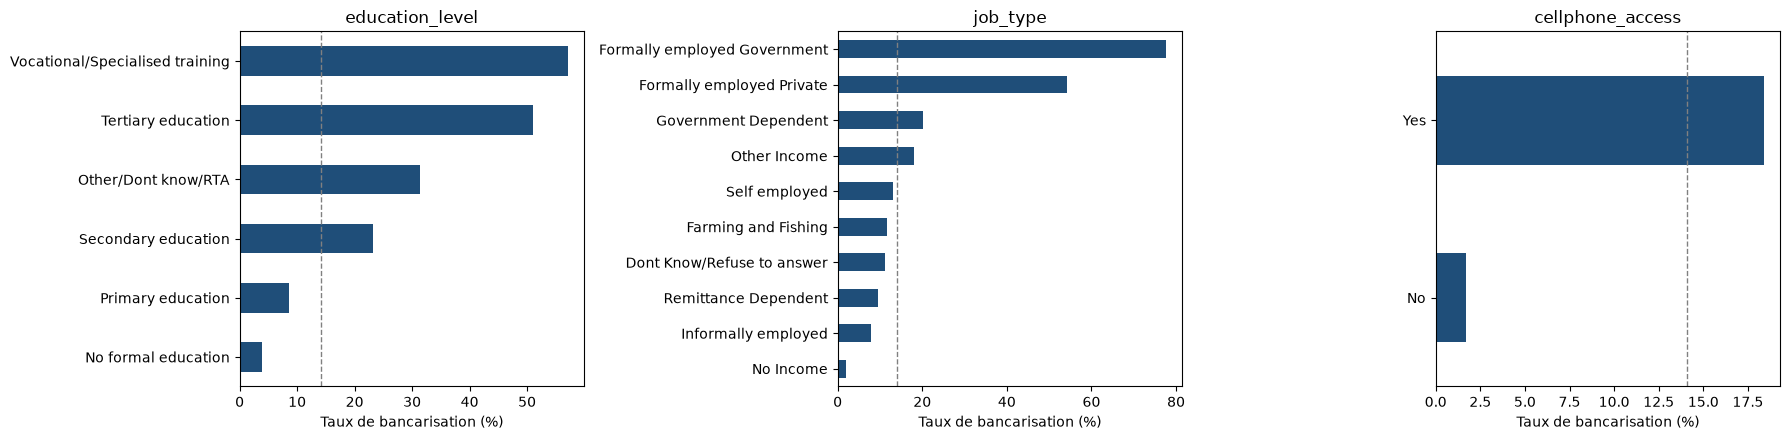

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["education_level", "job_type", "cellphone_access"]):
    t = df.groupby(col)["a_compte"].agg(effectif="count", taux="mean")
    print(t.round(3), "\n")
    (t["taux"] * 100).sort_values().plot(kind="barh", ax=ax, title=col, color="#1f4e79")
    ax.axvline(df["a_compte"].mean() * 100, color="grey", ls="--", lw=1)
    ax.set_xlabel("Taux de bancarisation (%)"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURES / "01_taux_bancarisation.png", dpi=120, bbox_inches="tight")
plt.show()

Q2.7 — Mes trois hypothèses :
1. L'éducation compte beaucoup : 3,9 % de comptes sans éducation, 51 % avec le supérieur.
2. Un emploi formel aide : 77,5 % chez les fonctionnaires, 2 % chez les personnes sans revenu.
3. Le téléphone est presque obligatoire : 18,4 % avec téléphone, 1,7 % sans.